# 00 Project Overview and Data Audit

**Scientific question.** Can the proposed benchmark be audited from original observations?

**Learning objectives.** Check input identity, measured units, overlap, and common scoring.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Course question, units, and integrity

Predict standardized vibration one sample ahead, then assess prediction accuracy,
compute, and fault-sensitive residual structure. A 3.2-kHz sample interval is
0.3125 ms. One prediction row at index $t$ is computed from earlier $x$ and RPM.
The shared assessment interval is $[1792,24000)$, meaning 22,208 scored targets.

Development validation provides a held-out segment. Fault records grouped by
MATLAB index support conditional analysis only. The inventory distinguishes files
absent now from inputs checked and eligible. Hashes verify identity, not
scientific representativeness. See Companion Chapters 1, 3, 6 and 13.

In [2]:
availability = evidence("results/data_availability.json")
display(pd.Series(availability, name="Intake finding").to_frame())
inputs = table("inputs/input_manifest.csv")
if inputs is not None:
    print(len(inputs), "source entries")
    display(inputs.head(6))

,Intake finding
sigtrain,True
sigvalid,True
sigfault1_count,200
sigfault1_excluded_overlap_indices_1based,"[61, 63]"
sigtest,False
sigfault2,False
fdt_featcal,True
confirmed_labels,False
acquisition_start_metadata,False
label_status,A/B are index groups only; no authoritative health labels supplied


33 source entries


,filename,original_path,role,bytes,sha256,mtime_utc,access_status,preprocessing_status,relation_to_other_sources
0,fdt_featcal.m,data/raw/fdt_featcal.m,course MATLAB reference,4115.0,6c1206b0cb7e1098b6b9b52cf437e2ba5097e05334e9c00cee51e5fc8fabbf06,2026-11-20T19:13:35.301814+00:00,READABLE,"reference code, not executed",NaN
1,sigfault1_part_001.mat,data/raw/sigfault1_part_001.mat,course measured input,7347291.0,a5554e18ff68f8fe50b48d6020ea818d279aa7ceed1f558cbd540526cceddede,2026-11-20T19:13:07.389720+00:00,READABLE,supplied processed 3.2 kHz; preserve stored x,NaN
2,sigfault1_part_002.mat,data/raw/sigfault1_part_002.mat,course measured input,7346281.0,a1d96948943512734ad5779dd2acfa2d9e0cfdcfa8870212fa074b511274372c,2026-11-20T19:13:08.251014+00:00,READABLE,supplied processed 3.2 kHz; preserve stored x,NaN
3,sigfault1_part_003.mat,data/raw/sigfault1_part_003.mat,course measured input,7345482.0,f1cccc900b8b0a0cd29e0deed493dee367ed963484ee0853b16b16c332314e14,2026-11-20T19:13:09.840976+00:00,READABLE,supplied processed 3.2 kHz; preserve stored x,NaN
4,sigfault1_part_004.mat,data/raw/sigfault1_part_004.mat,course measured input,7346358.0,b9f5d5763838dda8770e1dc4bcf250b2698fcd95e4ad549fb0a2e127c2ba576c,2026-11-20T19:13:06.377630+00:00,READABLE,supplied processed 3.2 kHz; preserve stored x,NaN
5,sigfault1_part_005.mat,data/raw/sigfault1_part_005.mat,course measured input,7346786.0,b133ebde2b89248dc1851bbfc484bc76d5a28a0370367545beeac85d9e26f920,2026-11-20T19:13:18.260380+00:00,READABLE,supplied processed 3.2 kHz; preserve stored x,NaN


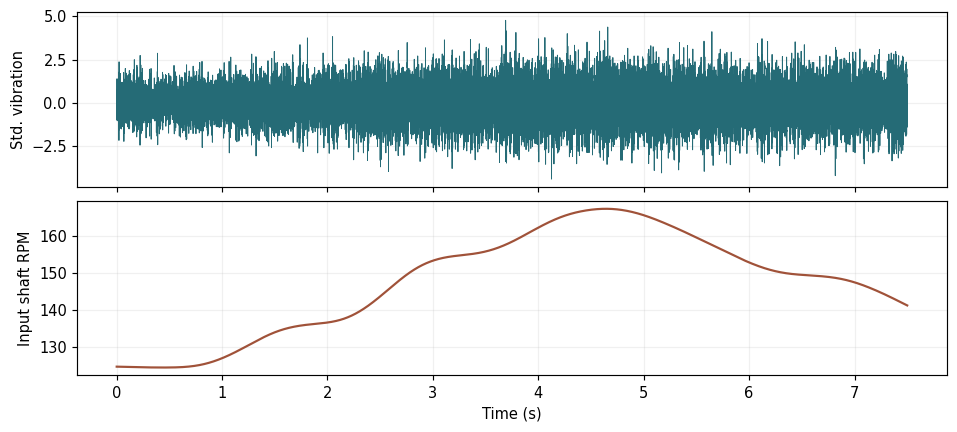

In [3]:
from src_gearbox.data import find_input, load_record

path = find_input(DATA, "sigtrain")
if path:
    record = load_record(path)
    np.testing.assert_allclose(np.diff(record.t), 1/record.fs, rtol=0, atol=2e-12)
    assert len(record.x) == N and record.fs == 3200
    axes = plt.subplots(2, 1, figsize=(9, 4), sharex=True, layout="constrained")[1]
    axes[0].plot(record.t, record.x, color="#256b76", lw=.65)
    axes[0].set_ylabel("Std. vibration")
    axes[1].plot(record.t, record.rpm, color="#a05239")
    axes[1].set(xlabel="Time (s)", ylabel="Input shaft RPM")
    plt.show()
else:
    show_fig("figures/eda/eda_speed.png")

In [4]:
normal = table("results/normalization_audit.csv")
if normal is not None:
    display(normal.head(4))
overlap = table("results/record_overlap_audit.csv")
if overlap is not None:
    print(len(overlap), "audit rows")
    display(overlap.head(6))
idx = np.arange(START, N, dtype="<i8")
print("Scored-index SHA-256", hashlib.sha256(idx.tobytes()).hexdigest())
assert idx.size == 22208 and idx[0] == 1792 and idx[-1] == 23999

,record_id,fields,x_mean,x_std_population,stored_x_mean_channel1,stored_x_std_channel1,raw_reconstruction_max_abs_error,stored_rpm_min,stored_rpm_max,speed_norm_max_error_vs_train_bounds
0,sigtrain:001,N fs spd spdmax spdmin spdnorm t x xmean xraw xstd,-0.003080,1.040098,0.002622,0.425173,2.220446e-16,124.074555,167.337658,0.0
1,sigvalid:001,N fs spd spdmax spdmin spdnorm t x xmean xraw xstd,-0.011851,1.047268,0.002622,0.425173,2.220446e-16,124.074555,167.337658,0.0
2,sigfault1:001,N fs spd spdmax spdmin spdnorm t x,0.000003,1.023110,NaN,NaN,NaN,124.074555,167.337658,0.0
3,sigfault1:002,N fs spd spdmax spdmin spdnorm t x,-0.029931,1.026574,NaN,NaN,NaN,124.074555,167.337658,0.0


401 audit rows


,record_id,reference,windows_scanned,best_start_zero_based,best_end_exclusive,x_correlation,max_x_abs_difference,max_rpm_abs_difference,near_by_eps_1e_8,exact_full_length,exact_offset_count
0,sigvalid:001,sigtrain,1,0,24000,0.041291,6.983277,0.050611,False,False,0
1,sigfault1:001,sigtrain,8001,30,24030,0.087866,7.317321,0.232503,False,False,0
2,sigfault1:001,sigvalid,8001,3,24003,0.108643,6.950266,0.062272,False,False,0
3,sigfault1:002,sigtrain,8001,6,24006,0.079121,6.987532,0.117611,False,False,0
4,sigfault1:002,sigvalid,8001,15,24015,0.086265,5.832499,0.113698,False,False,0
5,sigfault1:003,sigtrain,8001,16,24016,0.097152,6.110678,0.097822,False,False,0


Scored-index SHA-256 1522c0a1b184b971b59763df3d827515370162751cc61209f025765039a89fb1


### Interpretation and limits

A longer diagnostic record may contain a designated excerpt. Exclusion acts on the
acquisition, so scores on superficially different windows cannot be mistaken for
independent evidence. Treat the raw and standardized channels as distinct scales.
*Next*: use the designated training data to derive controlled feature hypotheses.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).